In [2]:
import PyPreprocess
import importlib
import os, datetime, netCDF4
import numpy as np
import torch
import torch.nn.functional as F
import scipy
import matplotlib.pyplot as plt
importlib.reload(PyPreprocess)

<module 'PyPreprocess' from '/mnt/c/Users/user/Desktop/rnd/AISat/VolumeInversion/torched/PyPreprocess.py'>

In [3]:
cache_dir = 'SNAPNative_Greenland_s1'

if(True):
    dataset = PyPreprocess.Single_Dataset_SNAPbase(
        src_fn = "/mnt/c/Users/user/Desktop/slc_cache/251114rGreenland/ALPSRP060811420-L1.1.zip",
        cache_dir = cache_dir,
        read_nc = True,
        alos1_deskew = True
    ); dataset.cache()
else:
    dataset = PyPreprocess.Pair_Dataset_SNAPbase.load_cache(cache_dir)

'''slc_date = datetime.datetime.strptime(dataset.metadata['0dopp_t0'][0][:11], '%d-%b-%Y')
siconc_fn = [el for el in os.listdir('nextSim_cache') if 'siconc' in el and slc_date.strftime('_%Y-%m') in el][0]
siconc_ds = netCDF4.Dataset('nextSim_cache'+'/'+siconc_fn, 'r')

aux_lat, aux_lon = siconc_ds.variables['latitude'][:], siconc_ds.variables['longitude'][:] #1D arrays
siconc = torch.as_tensor(siconc_ds.variables['siconc'][0])
siconc[torch.isnan(siconc)] = 0

grid = torch.empty(1, dataset.lat.shape[0], dataset.lat.shape[1], 2, dtype=siconc.dtype)
grid[..., 0] = torch.as_tensor(2 * (dataset.lat - aux_lat[0])/(aux_lat[-1]-aux_lat[0]) - 1)*4
grid[..., 1] = torch.as_tensor(2 * (dataset.lon - aux_lon[0])/(aux_lon[-1]-aux_lon[0]) - 1)*4

siconc_b = F.grid_sample(siconc[None,None,:,:].to(torch.float32), tinygrid[None,...])

plt.imshow(siconc_b[0,0], aspect=0.1)'''

print(dataset.slc.shape)

located cache at SNAPNative_Greenland_s1
extracting parameters...
retrieved metadata.
retrieved SLC complex.
rescaling auxiliary data...
all parameters extracted.
dataset loaded.
(4, 18432, 1248)


In [164]:
#plt.imshow(dataset.rg, aspect=0.05)
#dataset.rg[0,-1] - dataset.rg[0,0]
slc_fft = torch.fft.fftshift(torch.fft.fft(torch.as_tensor(dataset.slc).to(torch.complex64), dim=1), dim=1)

# step 1 - smooth amplitude distribution
std = slc_fft.shape[1] // 20 #1/20 amplitude radius as std for much smoothing
g_kern = torch.exp(-(torch.arange(6*std)-3*std)**2/(2*std**2))/(6*std); g_kern /= g_kern.sum()
azi_bin_mag = torch.abs(slc_fft).sum(dim=2)
for i in range(azi_bin_mag.shape[0]): azi_bin_mag[i][azi_bin_mag[i] < azi_bin_mag[i].mean()] = azi_bin_mag[i].mean()
azi_bin_mag = F.conv1d(F.pad(azi_bin_mag[:,None], (3*std,3*std), mode='reflect'), g_kern[None,None,:].repeat(azi_bin_mag.shape[0],1,1))[0]
azi_bin_mag = azi_bin_mag[:,:slc_fft.shape[1]] / azi_bin_mag[:,:slc_fft.shape[1]].max(dim=1)[0][:,None]

# step 2 - fit hamming window
fp = torch.nn.Parameter(torch.tensor([0.5,0,-0.8,0.8], requires_grad=True, dtype=torch.float))
optimizer = torch.optim.Adam([fp], lr=0.05);
for i in range(50):
    optimizer.zero_grad()
    hamc = torch.stack((torch.zeros(slc_fft.shape[1]),fp[2] + (fp[3] - fp[2]) * torch.linspace(0,1,slc_fft.shape[1])), dim=-1)
    ham = fp[0] - (1 - fp[0]) * torch.cos(2 * torch.pi * torch.arange(1000) / 999)
    ham = F.grid_sample(ham[None,None,:,None], hamc[None,:,None,:], mode='bilinear', align_corners=True)[:,0,:,0] + fp[1]
    loss = ((azi_bin_mag**4 - ham**4)**2).mean()
    loss.backward(); optimizer.step()

# step 3 - regularize
slc_fft = slc_fft / ham[...,None].detach()

# step 4 - subaperture split
sub_n = slc_fft.shape[1]//3
slc_sub_fft = torch.stack((slc_fft[:, slc_fft.shape[1]//2 - sub_n : slc_fft.shape[1]//2],
                           slc_fft[:, slc_fft.shape[1]//2 : slc_fft.shape[1]//2 + sub_n]), dim=0)
slc_sub_fft *= torch.hamming_window(sub_n, False, alpha=0.75)[None,None,:,None]

# step 5 - generate subaperture
slc_sub = torch.fft.ifft(slc_sub_fft, dim=2)

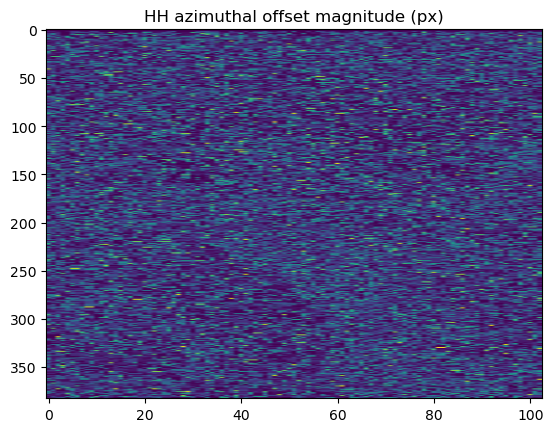

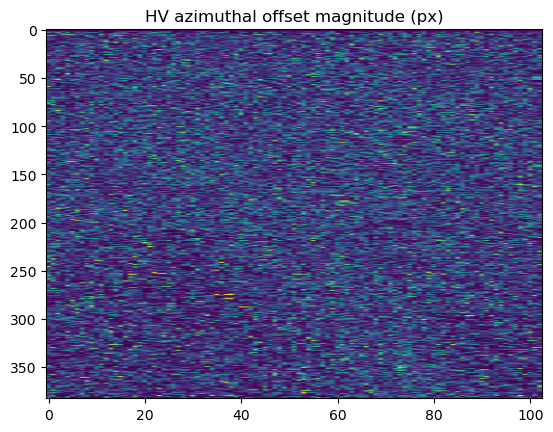

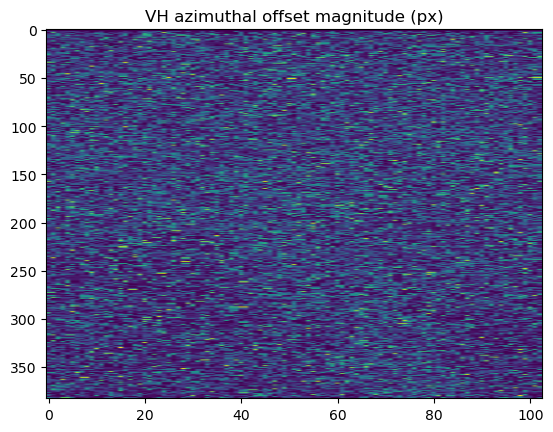

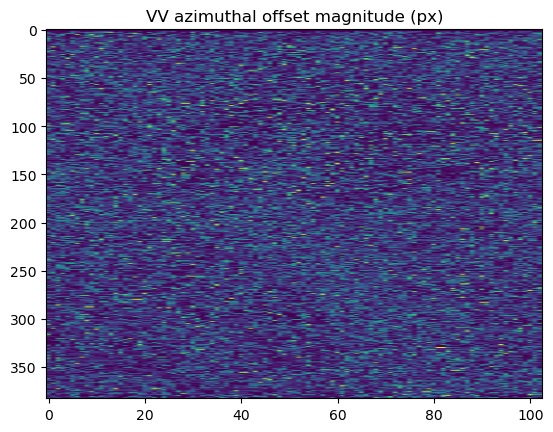

In [126]:
import subaperture
importlib.reload(subaperture)

tmp = subaperture.slc_mda_drift_blocks(dataset.slc, device='cpu', rg_cut=0.3)

tmp = tmp.numpy()
plt.imshow(np.abs(tmp[0]), aspect=0.2); plt.title("HH azimuthal offset magnitude (px)"); plt.show()
plt.imshow(np.abs(tmp[1]), aspect=0.2); plt.title("HV azimuthal offset magnitude (px)"); plt.show()
plt.imshow(np.abs(tmp[2]), aspect=0.2); plt.title("VH azimuthal offset magnitude (px)"); plt.show()
plt.imshow(np.abs(tmp[3]), aspect=0.2); plt.title("VV azimuthal offset magnitude (px)"); plt.show()

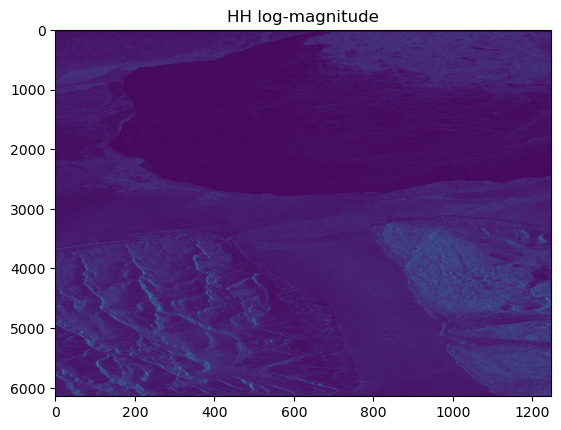

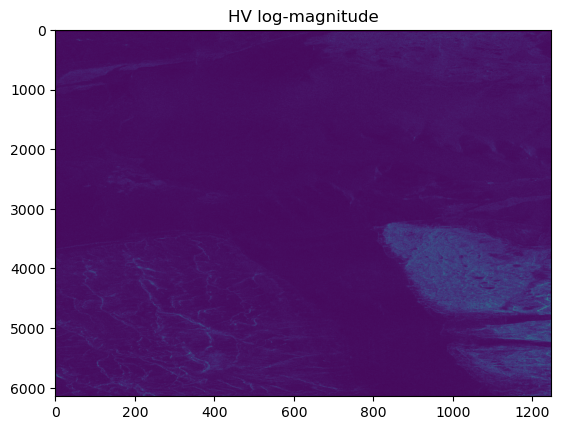

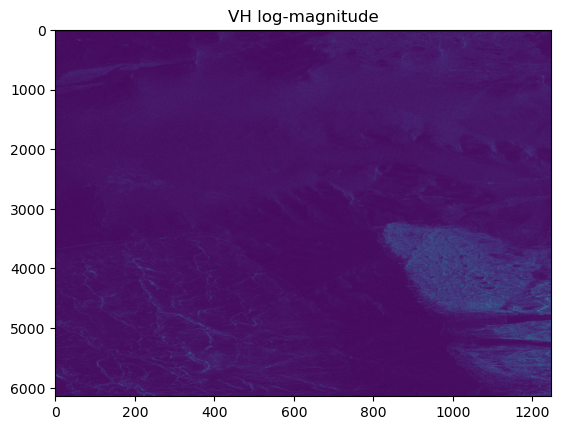

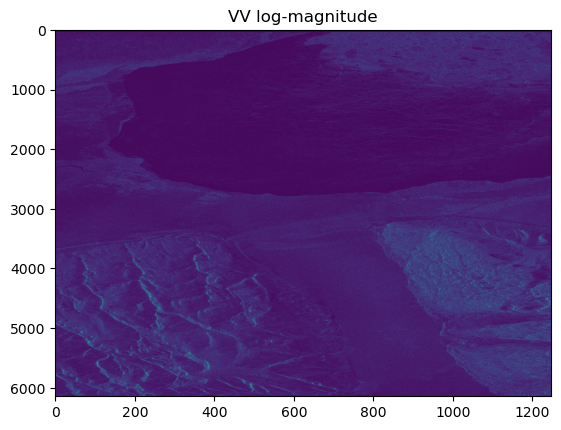

In [129]:
importlib.reload(subaperture)
tmp = np.log1p(np.abs(subaperture.slc2sub2(dataset.slc)[0].detach().cpu().numpy()))
plt.imshow(tmp[0], aspect=0.15); plt.title('HH log-magnitude'); plt.show()
plt.imshow(tmp[1], aspect=0.15); plt.title('HV log-magnitude'); plt.show()
plt.imshow(tmp[2], aspect=0.15); plt.title('VH log-magnitude'); plt.show()
plt.imshow(tmp[3], aspect=0.15); plt.title('VV log-magnitude'); plt.show()

In [262]:
import Model_IceVVHHr
'''
RETRIEVE ICE REFRACTIVE INDEX PARAMETER (for thickness inversion using autofocus algorithm)
'''

qpol = torch.as_tensor(dataset.slc).to(torch.complex64)

vvhhr = (torch.abs(qpol[3])/torch.abs(qpol[0])).clone().to(torch.float32).to('cuda')
tmp_c = torch.stack(torch.meshgrid(torch.linspace(-1,1,vvhhr.shape[0]),torch.linspace(-1,1,vvhhr.shape[1]),indexing='ij'), dim=-1)
ia = torch.deg2rad(F.grid_sample(torch.as_tensor(dataset.ia)[None,None,], tmp_c[None,], align_corners=True))[0,0].to('cuda')

In [237]:
importlib.reload(Model_IceVVHHr)

m_vvhhr = Model_IceVVHHr.IceVVHHr(qpol).to('cuda')
optimizer = torch.optim.Adam(m_vvhhr.parameters(), lr=0.01)

for i in range(100):
    optimizer.zero_grad()
    loss = torch.nanmean((m_vvhhr(ia) - vvhhr)**2)
    loss.backward()
    optimizer.step()

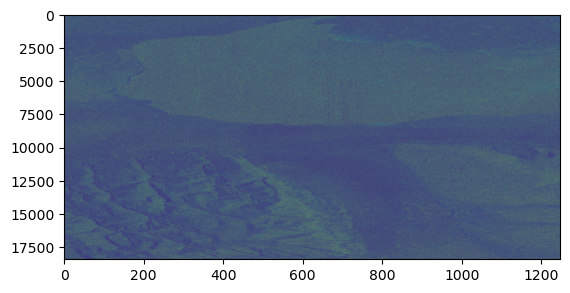

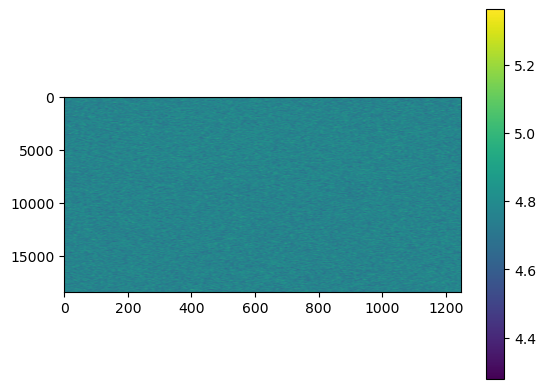

In [247]:
#torch.nansum(m_vvhhr(ia))
#torch.nansum(vvhhr)
#torch.isnan(m_vvhhr(ia))
plt.imshow((m_vvhhr.stdv.detach().cpu().numpy()), aspect=0.1/3); plt.show()
plt.imshow(scipy.ndimage.gaussian_filter(m_vvhhr.rdie.detach().cpu().numpy(), 3), aspect=0.1/3); plt.colorbar(); plt.show()

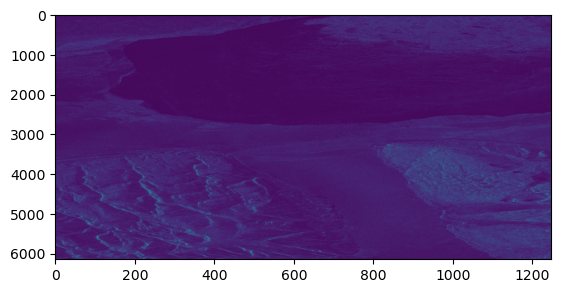

In [195]:
#plt.plot(torch.abs().sum(dim=2)[0])
#plt.plot(azi_bin_mag[0])
#plt.plot(azi_bin_mag[0])
#plt.plot(ham[0].detach().numpy())
plt.imshow(np.log1p(np.abs(slc_sub[1,0].detach().numpy())), aspect=0.1)

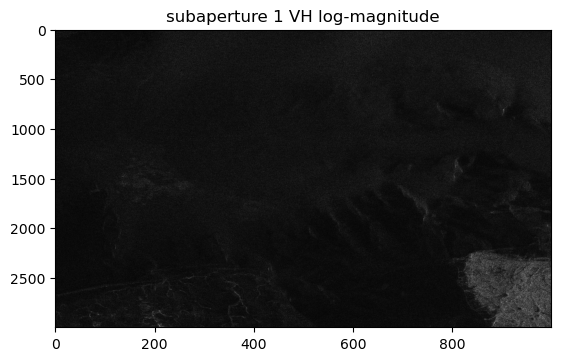

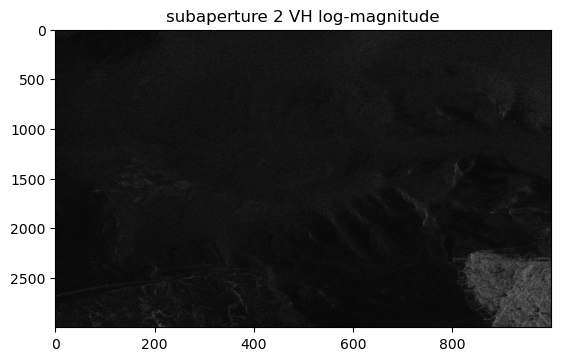

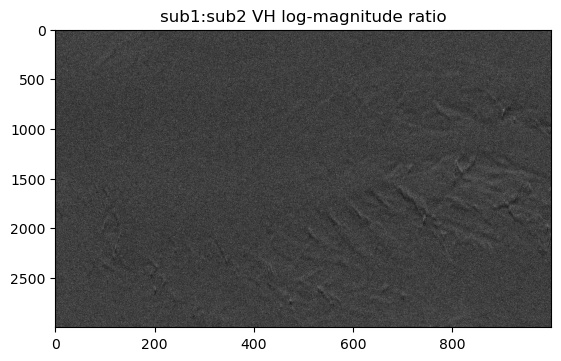

In [712]:
i = 2
tmp = ['HH','HV','VH','VV']
plt.imshow(np.log1p(np.abs(slc_sub[0,i,1000:4000,:1000].numpy())), aspect=0.2, cmap='gray'); plt.title(f'subaperture 1 {tmp[i]} log-magnitude'); plt.show()
plt.imshow(np.log1p(np.abs(slc_sub[1,i,1000:4000,:1000].numpy())), aspect=0.2, cmap='gray'); plt.title(f'subaperture 2 {tmp[i]} log-magnitude'); plt.show()
plt.imshow(np.log1p(np.log1p(np.abs(np.log1p(slc_sub[0,i,1000:4000,:1000].numpy())) /
           np.abs(np.log1p(slc_sub[1,i,1000:4000,:1000].numpy())))), aspect=0.2, cmap='gray'); plt.title(f'sub1:sub2 {tmp[i]} log-magnitude ratio'); plt.show()